# Experiment 6 — Decision Tree and Random Forest

**Aim:** Train and compare a Decision Tree and Random Forest classifier.

**Libraries:** pandas, NumPy, Matplotlib, and scikit-learn.

**Theory:** Decision trees recursively partition feature space and can overfit when unrestricted. Random Forest averages randomized trees to reduce variance.

**Dataset:** Titanic passenger data (local copy: `datasets/titanic_data.csv`).

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42

for candidate in [Path("datasets"), Path("../datasets")]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError("datasets/ folder not found")

for candidate in [Path("outputs"), Path("../outputs")]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

FIG_DIR = OUTPUT_DIR / "figures"
RES_DIR = OUTPUT_DIR / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the dataset, select useful columns, handle missing values

Columns used: `Pclass` (1 = first, 2 = second, 3 = third), `Sex`, `Age`, `Fare`, with `Survived` as the target. Only `Age` has missing values; they are filled with the **median of the training set** (computed after the split, so test data does not leak into training).

In [2]:
df = pd.read_csv(DATA_DIR / "titanic_data.csv")
print("Full dataset shape:", df.shape)

data = df[["Pclass", "Sex", "Age", "Fare", "Survived"]].copy()
print("\nMissing values before handling:")
print(data.isna().sum())

data["Sex"] = data["Sex"].map({"male": 0, "female": 1})

X = data.drop(columns=["Survived"])
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

age_median = X_train["Age"].median()
X_train["Age"] = X_train["Age"].fillna(age_median)
X_test["Age"] = X_test["Age"].fillna(age_median)

print(f"\nTrain size: {len(X_train)} | Test size: {len(X_test)}")
print(f"Age missing values left -> train: {X_train['Age'].isna().sum()}, test: {X_test['Age'].isna().sum()}")

Full dataset shape: (891, 12)

Missing values before handling:
Pclass        0
Sex           0
Age         177
Fare          0
Survived      0
dtype: int64

Train size: 712 | Test size: 179
Age missing values left -> train: 0, test: 0


## 2. Train a Decision Tree and visualise it

The tree below is limited to `max_depth = 3` so it stays readable. `Sex` and `Fare`/`Pclass` appear near the top of the tree.

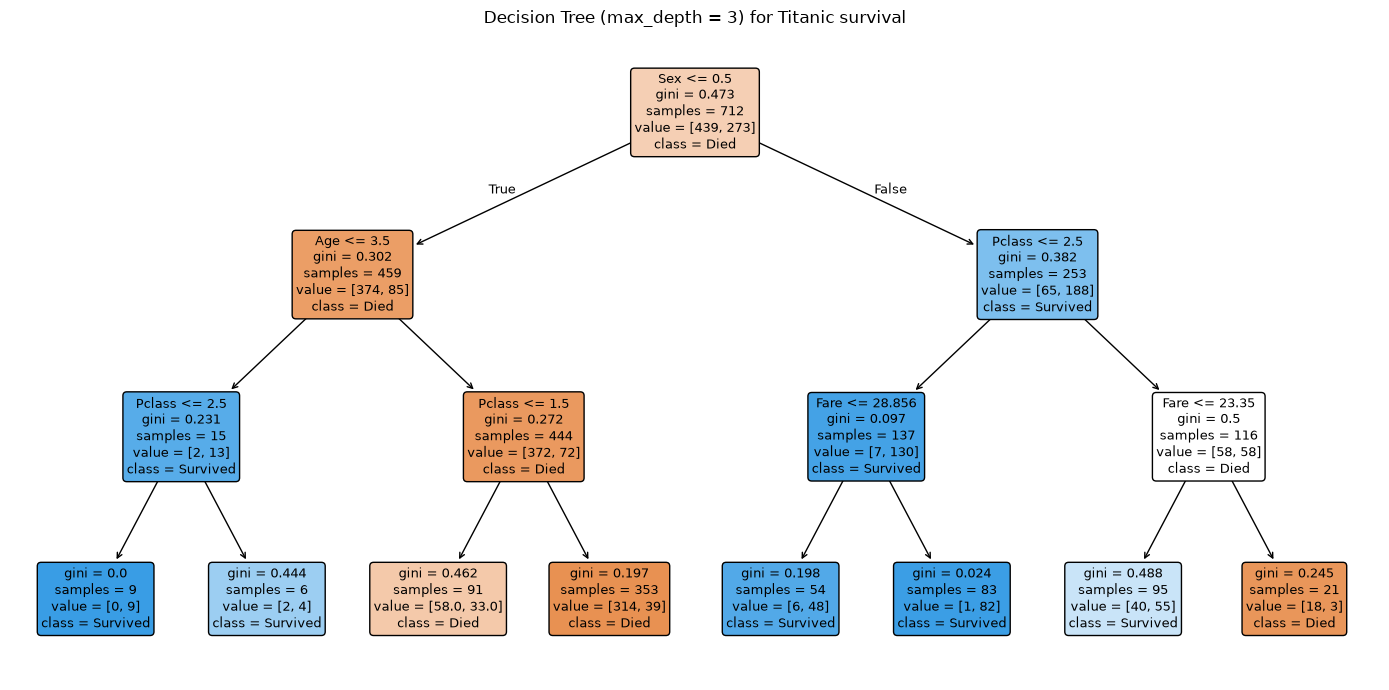

In [3]:
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree_clf.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(
    tree_clf,
    feature_names=X_train.columns.tolist(),
    class_names=["Died", "Survived"],
    filled=True,
    rounded=True,
    ax=ax,
)
ax.set_title("Decision Tree (max_depth = 3) for Titanic survival")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp06_tree_depth3.png", dpi=150)
plt.show()

## 3. Try different `max_depth` values

Accuracy is compared on both the training and test sets. A very deep tree (`None`) fits the training data almost perfectly but does no better on the test data — a classic sign of overfitting.

max_depth  train_accuracy  test_accuracy
        2        0.804775       0.759777
        3        0.825843       0.793296
        4        0.831461       0.776536
        5        0.865169       0.765363
     None        0.981742       0.798883


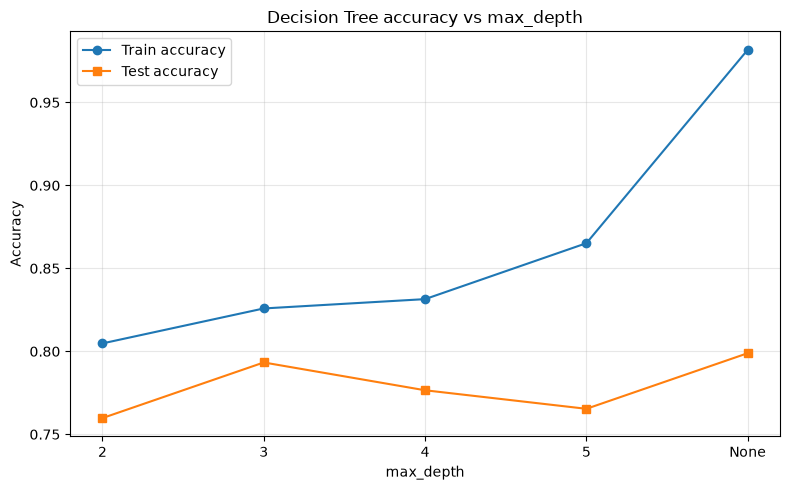

In [4]:
depths = [2, 3, 4, 5, None]
rows = []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    clf.fit(X_train, y_train)
    rows.append({
        "max_depth": "None" if d is None else d,
        "train_accuracy": accuracy_score(y_train, clf.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, clf.predict(X_test)),
    })

depth_df = pd.DataFrame(rows)
print(depth_df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(depth_df["max_depth"].astype(str), depth_df["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(depth_df["max_depth"].astype(str), depth_df["test_accuracy"], marker="s", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree accuracy vs max_depth")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp06_tree_depth_accuracy.png", dpi=150)
plt.show()

## 4. Train a Random Forest and compare with the single tree

In [5]:
forest_clf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
forest_clf.fit(X_train, y_train)

tree_test_acc = accuracy_score(y_test, tree_clf.predict(X_test))
forest_test_acc = accuracy_score(y_test, forest_clf.predict(X_test))

comparison = pd.DataFrame([
    {"Model": "Decision Tree (depth 3)", "Test accuracy": tree_test_acc},
    {"Model": "Random Forest (100 trees)", "Test accuracy": forest_test_acc},
])
print(comparison.to_string(index=False))

                    Model  Test accuracy
  Decision Tree (depth 3)       0.793296
Random Forest (100 trees)       0.826816


## 5. Feature importances

The Random Forest reports how much each feature contributed to its decisions across all trees.

Fare      0.332754
Sex       0.287982
Age       0.283848
Pclass    0.095416


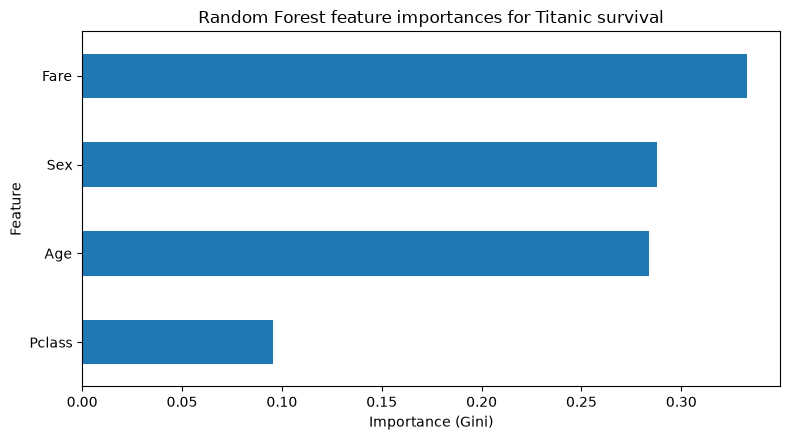

In [6]:
importances = pd.Series(forest_clf.feature_importances_, index=X_train.columns)
importances = importances.sort_values()
print(importances.sort_values(ascending=False).to_string())

plt.figure(figsize=(8, 4.5))
importances.plot(kind="barh")
plt.xlabel("Importance (Gini)")
plt.ylabel("Feature")
plt.title("Random Forest feature importances for Titanic survival")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp06_feature_importances.png", dpi=150)
plt.show()

## Observation

Based on the run above:

1. Of the single decision trees, `max_depth=3` gave **79.3% test accuracy**; the unlimited tree reached 98.2% train accuracy but only 79.9% test accuracy — clear **overfitting**, and extra depth did not buy reliable test performance (depths 4 and 5 actually scored lower on the test set).
2. The **Random Forest (100 trees) scored 82.7%**, beating every single tree — averaging many decorrelated trees reduces variance and stabilises predictions.
3. Feature importances: **Fare is the most important feature (0.333)**, followed by Sex (0.288) and Age (0.284); Pclass contributes least (0.095). In the visualised depth-3 tree, **Sex is the root split**, with Age, Pclass and Fare making the deeper splits — consistent with the well-known pattern that women survived more often.
4. 177 missing Age values (~20%) were filled with the training median, which keeps the split leak-free but dilutes Age's individual signal.

## Result

The executed cells above provide the measured result for this experiment. The conclusion should be interpreted using the dataset and evaluation limits stated here.